# Prepare for analysis - get models

**Load modules**

In [1]:
import requests
import reframed
import pandas as pd
import warnings

import matplotlib.pyplot as plt
from os import listdir

### E. coli auxotrophs (Guillen et al. 2021) 

**Load model**

In [2]:
# Load curated model from Bernstein et al (2023)
url = "https://github.com/dbernste/E_coli_GEM_validation/raw/refs/heads/main/Analysis/iML1515_model_adjusted_all_corrections.xml"
response = requests.get(url)

if response.status_code == 200:
    with open("../models/Guillen2021/iML1515.xml", "wb") as f:
        f.write(response.content)
else:
    print("Failed to download the file. Check the URL.")

model_ecoli = reframed.load_cbmodel("../models/Guillen2021/iML1515.xml")

Map gene id to name

In [3]:
id2name = {}
for gene in model_ecoli.genes:
    id2name[gene] = model_ecoli.genes[gene].name

id2name_ser = pd.Series(id2name)
id2name_ser.name="name"
id2name_ser.index.name="id"
id2name_ser.to_csv("../data/Guillen2021/generated/gene_id2name.tsv",sep="\t")

**Experimental relative abundance from Guillen et al (2021)**

In [4]:
# NB! yhhK in data == panZ in paper
relative_abundance = pd.read_csv("../data/Guillen2021/relative_abundance.csv",index_col=0)
relative_abundance.index =relative_abundance.index.map(lambda x:x if x!="yhhK" else "panZ")

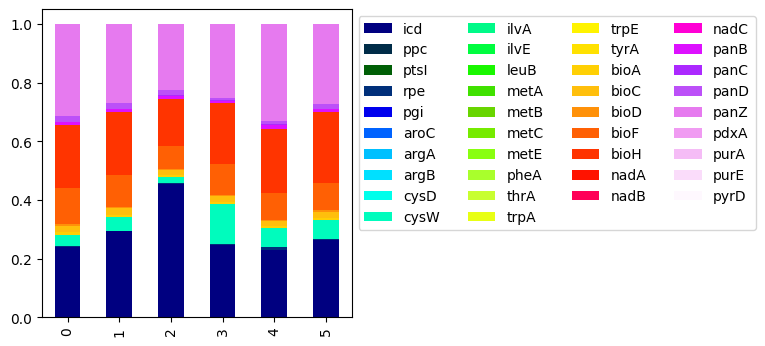

In [5]:
ax = relative_abundance.T.plot.bar(stacked=True,cmap="gist_ncar",figsize=(4,4))

plt.legend(loc="upper left", ncol=len(relative_abundance.index)/8,bbox_to_anchor=(1,1))

In [6]:
relative_abundance.T.mean().sort_values(ascending=False).head(10)

icd     0.287848
panZ    0.276678
bioH    0.211130
bioF    0.098526
cysW    0.062219
bioC    0.020200
panD    0.015948
panB    0.009927
bioA    0.007043
bioD    0.005411
dtype: float64

**Generate models for each E.coli strain**

NB! Removing the gene for panD instead because panZ is a regulatory protein.

In [7]:
name2id_38 = id2name_ser[id2name_ser.isin(relative_abundance.index)]\
                .reset_index()\
                .set_index("name")["id"]\
                .to_dict()

In [8]:
# additional details for special cases
name2id_38["panZ"]=name2id_38["panD"] # panZ is a regulatory protein for panD
model_ecoli.reactions.R_SULabcpp.gpr.proteins.pop(1) # Remove molybdate genes
model_ecoli.add_reaction_from_str("R_PNTOtex2: M_pnto__R_c --> M_pnto__R_e")
model_ecoli.add_reaction_from_str("R_BTNtex2: M_btn_c --> M_btn_e")
model_ecoli.update()  

# make models
ecoli_models = {}

for name,id_ in name2id_38.items():
    if name=="cysW": # Special case: cysW - also remove cysZ
        ecoli_models[name] = reframed.hard_knockout(model_ecoli,[id_,"G_b2413"],
                                                    rename="mutant_"+name) #remove cysZ gene
    else: 
        ecoli_models[name] = reframed.hard_knockout(model_ecoli,[id_],rename="mutant_"+name)

In [9]:
gene1 = "panD"
gene2 = "panD"
for rxn in ecoli_models[gene1].get_reactions_by_gene(name2id_38[gene2]):
    lb = ecoli_models[gene1].reactions[rxn].lb
    ub = ecoli_models[gene1].reactions[rxn].ub
    print(f"{rxn} flux constrained for {gene1} reactions: {(lb,ub)}")

gene1 = "panD"
gene2 = "icd"
for rxn in ecoli_models[gene1].get_reactions_by_gene(name2id_38[gene2]):
    lb = ecoli_models[gene1].reactions[rxn].lb
    ub = ecoli_models[gene1].reactions[rxn].ub
    print(f"{rxn} flux NOT constrained for {gene2}: {(lb,ub)}")

R_ASP1DC flux constrained for panD reactions: (0, 0)
R_ICDHyr flux NOT constrained for icd: (-inf, inf)


**Save models**

In [10]:
for name,model in ecoli_models.items():
    reframed.save_cbmodel(model,"../models/Guillen2021/strains/"+model.id+".xml")

### Gut microbiome (Venturelli et al. 2018) 

Models for relevant species were collected from the AGORA2 database ([sbml_files_fixed](https://vmh.life/files/reconstructions/AGORA2/version2.01/))

**Load models**

In [11]:
models = {}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    for path in listdir("../models/Venturelli2018/species_used/"):
        models[path[:-4]] = reframed.load_cbmodel("../models/Venturelli2018/species_used/"+path,exchange_detection="R_EX_(?!biomass__40__e__41__)")
    

**Remove O2 metabolites - because of anaerobic environment**

In [12]:
new_models = {}

for name,model in models.items():
    if "M_o2__91__e__93__" in model.metabolites:
        print(name)
        model.remove_metabolite("M_o2__91__e__93__")
    model.update()
    
    reframed.save_cbmodel(model,"../models/Venturelli2018/species_used_noO2/"+name+".xml")


Bacteroides_uniformis_ATCC_8492
Bacteroides_vulgatus_ATCC_8482
Collinsella_aerofaciens_ATCC_25986
Faecalibacterium_prausnitzii_A2_165
Eggerthella_lenta_DSM_2243
Prevotella_copri_CB7_DSM_18205
Clostridium_hiranonis_TO_931_DSM_13275
Eubacterium_rectale_ATCC_33656
Desulfovibrio_piger_ATCC_29098
Bacteroides_ovatus_ATCC_8483
Bacteroides_thetaiotaomicron_VPI_5482
Blautia_hydrogenotrophica_DSM_10507
